In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Chargement du fichier Advertising.csv
df = pd.read_csv('Advertising.csv')

# Si une colonne d'index inutile 'Unnamed: 0' existe, on la supprime
if 'Unnamed: 0' in df.columns:
    df.drop('Unnamed: 0', axis=1, inplace=True)

print("--- Aperçu des données ---")
df.head()

--- Aperçu des données ---


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


--- Informations sur le dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB

--- Vérification des valeurs manquantes ---
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


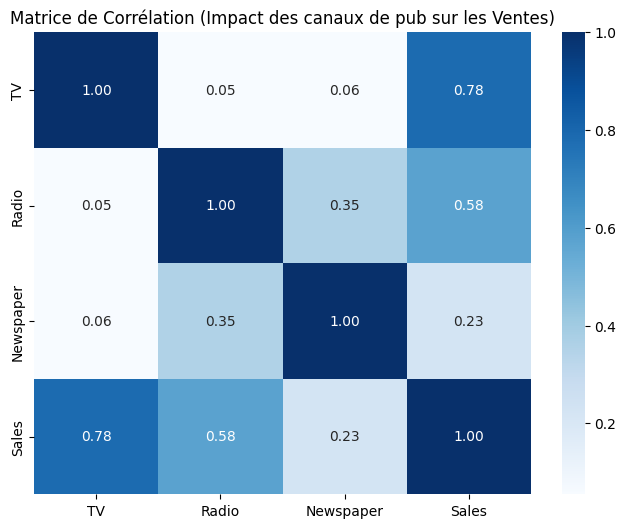

In [5]:
# Informations générales et vérification des valeurs manquantes
print("--- Informations sur le dataset ---")
df.info()

print("\n--- Vérification des valeurs manquantes ---")
print(df.isnull().sum())

# Matrice de corrélation
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Matrice de Corrélation (Impact des canaux de pub sur les Ventes)')
plt.show()

In [6]:
from sklearn.model_selection import train_test_split

# Variables explicatives (Publicités TV, Radio, Journal) et Variable cible (Sales)
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

# Séparation 80% entraînement / 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Taille de X_train : {X_train.shape}")
print(f"Taille de X_test : {X_test.shape}")

Taille de X_train : (160, 3)
Taille de X_test : (40, 3)


In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 1. Régression Linéaire
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

# 2. Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

# Évaluation des performances
print("=== Performances du Modèle Linear Regression ===")
print(f"Score R² : {r2_score(y_test, lr_pred):.4f}")
print(f"MAE : {mean_absolute_error(y_test, lr_pred):.4f}")

print("\n=== Performances du Modèle Random Forest ===")
print(f"Score R² : {r2_score(y_test, rf_pred):.4f}")
print(f"MAE : {mean_absolute_error(y_test, rf_pred):.4f}")

=== Performances du Modèle Linear Regression ===
Score R² : 0.8994
MAE : 1.4608

=== Performances du Modèle Random Forest ===
Score R² : 0.9813
MAE : 0.6201


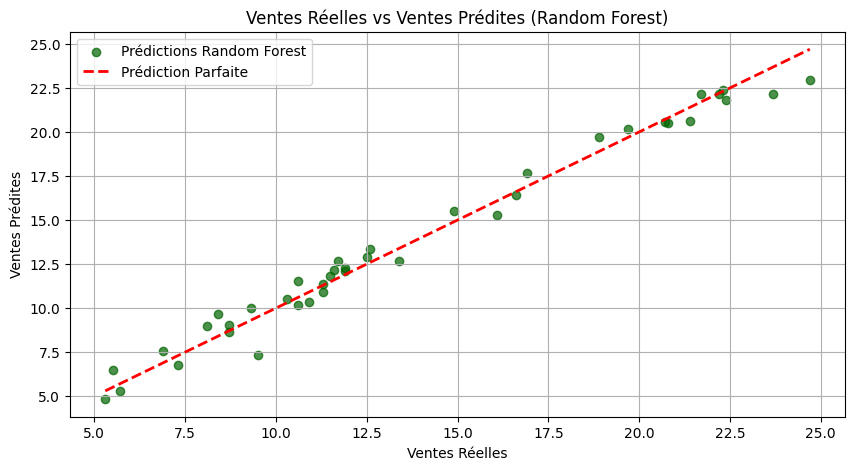

In [8]:
plt.figure(figsize=(10, 5))

plt.scatter(y_test, rf_pred, color='darkgreen', alpha=0.7, label='Prédictions Random Forest')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Prédiction Parfaite')

plt.xlabel('Ventes Réelles')
plt.ylabel('Ventes Prédites')
plt.title('Ventes Réelles vs Ventes Prédites (Random Forest)')
plt.legend()
plt.grid(True)
plt.show()